<a href="https://colab.research.google.com/github/PawanSingh130901/Pawan-Singh/blob/main/eda23bds0041.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

# 1. Loading the dataset
url = 'https://raw.githubusercontent.com/salemprakash/EDA/main/Data/GSS7402.csv'
df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset Shape: (9120, 11)


,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant
0,1,0,25,14,2002,1,NaN,cauc,no,no,no
1,2,1,30,13,2002,4,19.0,cauc,yes,no,no
2,3,1,55,2,2002,1,27.0,cauc,no,no,yes
3,4,2,57,16,2002,1,22.0,cauc,no,no,no
4,5,2,71,12,2002,6,29.0,cauc,yes,no,no


In [3]:
print("\n--- Data Types and Non-Null Counts ---")
df.info()

print("\n--- Summary Statistics (Numerical) ---")
display(df.describe())

print("\n--- Summary Statistics (Categorical) ---")
display(df.describe(include=['object', 'category']))


--- Data Types and Non-Null Counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9120 entries, 0 to 9119
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   rownames       9120 non-null   int64  
 1   kids           9120 non-null   int64  
 2   age            9120 non-null   int64  
 3   education      9120 non-null   int64  
 4   year           9120 non-null   int64  
 5   siblings       9120 non-null   int64  
 6   agefirstbirth  3312 non-null   float64
 7   ethnicity      9120 non-null   object 
 8   city16         9120 non-null   object 
 9   lowincome16    9120 non-null   object 
 10  immigrant      9120 non-null   object 
dtypes: float64(1), int64(6), object(4)
memory usage: 783.9+ KB

--- Summary Statistics (Numerical) ---


,rownames,kids,age,education,year,siblings,agefirstbirth
count,9120.000000,9120.000000,9120.000000,9120.000000,9120.000000,9120.000000,3312.000000
mean,4560.500000,2.076096,46.082018,12.635088,1990.288596,4.050658,22.630737
std,2632.861561,1.805099,17.923889,2.955190,9.096915,3.246137,4.859220
min,1.000000,0.000000,18.000000,0.000000,1974.000000,0.000000,9.000000
25%,2280.750000,1.000000,31.000000,12.000000,1982.000000,2.000000,19.000000
50%,4560.500000,2.000000,43.000000,12.000000,1994.000000,3.000000,22.000000
75%,6840.250000,3.000000,59.000000,14.000000,1998.000000,6.000000,25.000000
max,9120.000000,8.000000,89.000000,20.000000,2002.000000,35.000000,42.000000



--- Summary Statistics (Categorical) ---


,ethnicity,city16,lowincome16,immigrant
count,9120,9120,9120,9120
unique,2,2,2,2
top,cauc,no,no,no
freq,7335,5246,7182,8122


In [4]:
print("Missing values before handling:\n", df.isnull().sum())

# Separate columns by data type
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = df.select_dtypes(include=['object', 'category']).columns

# Strategy: Fill numerical missing values with the median
for col in num_cols:
    df[col].fillna(df[col].median(), inplace=True)

# Strategy: Fill categorical missing values with the mode (most frequent value)
for col in cat_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

print("\nMissing values after handling:\n", df.isnull().sum())

Missing values before handling:
 rownames            0
kids                0
age                 0
education           0
year                0
siblings            0
agefirstbirth    5808
ethnicity           0
city16              0
lowincome16         0
immigrant           0
dtype: int64

Missing values after handling:
 rownames         0
kids             0
age              0
education        0
year             0
siblings         0
agefirstbirth    0
ethnicity        0
city16           0
lowincome16      0
immigrant        0
dtype: int64


In [5]:
# Check for and drop exact duplicate rows
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows found: {duplicates}")

if duplicates > 0:
    df.drop_duplicates(inplace=True)
    print("Duplicates removed. New shape:", df.shape)

Number of duplicate rows found: 0


In [6]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
for col in cat_cols:
    # We create a new encoded column to preserve the original for certain visualizations
    df[col + '_encoded'] = le.fit_transform(df[col].astype(str))

print("Data Transformation complete. Updated columns:")
display(df.head())

Data Transformation complete. Updated columns:


,rownames,kids,age,education,year,siblings,agefirstbirth,ethnicity,city16,lowincome16,immigrant,ethnicity_encoded,city16_encoded,lowincome16_encoded,immigrant_encoded
0,1,0,25,14,2002,1,22.0,cauc,no,no,no,0,0,0,0
1,2,1,30,13,2002,4,19.0,cauc,yes,no,no,0,1,0,0
2,3,1,55,2,2002,1,27.0,cauc,no,no,yes,0,0,0,1
3,4,2,57,16,2002,1,22.0,cauc,no,no,no,0,0,0,0
4,5,2,71,12,2002,6,29.0,cauc,yes,no,no,0,1,0,0


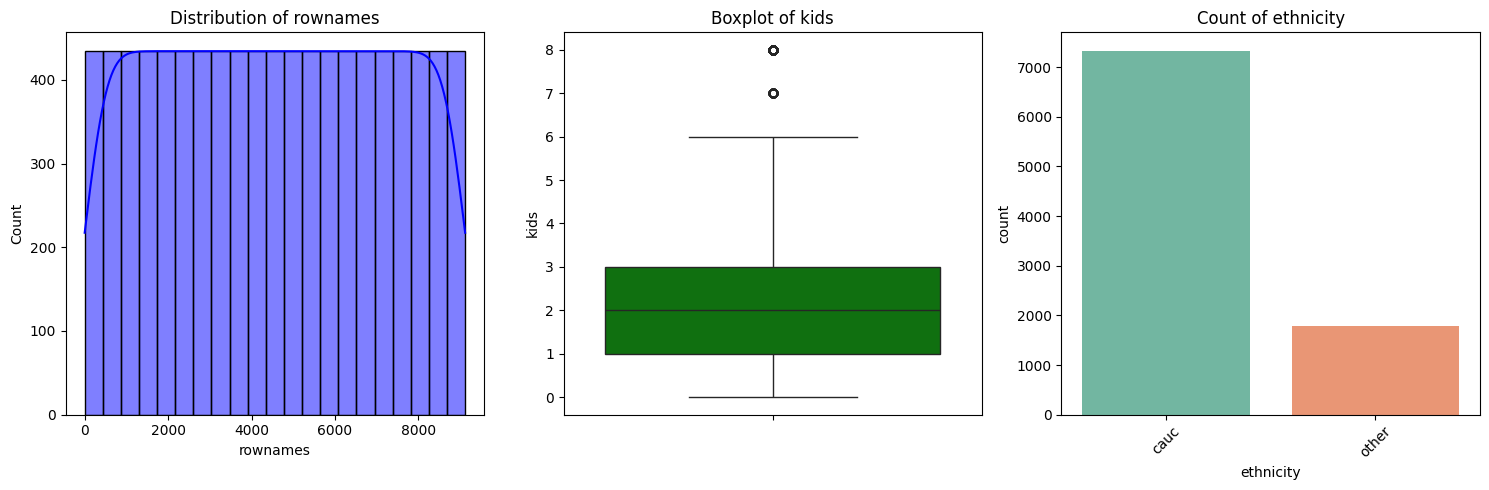

In [7]:
# Visualizing single variables independently
plt.figure(figsize=(15, 5))

# Plot 1: Histogram of the first numerical column
plt.subplot(1, 3, 1)
sns.histplot(df[num_cols[0]], kde=True, color='blue')
plt.title(f'Distribution of {num_cols[0]}')

# Plot 2: Boxplot of the second numerical column (if available, else reuse first)
col2 = num_cols[1] if len(num_cols) > 1 else num_cols[0]
plt.subplot(1, 3, 2)
sns.boxplot(y=df[col2], color='green')
plt.title(f'Boxplot of {col2}')

# Plot 3: Countplot of the first categorical column
plt.subplot(1, 3, 3)
sns.countplot(x=df[cat_cols[0]], palette='Set2')
plt.title(f'Count of {cat_cols[0]}')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

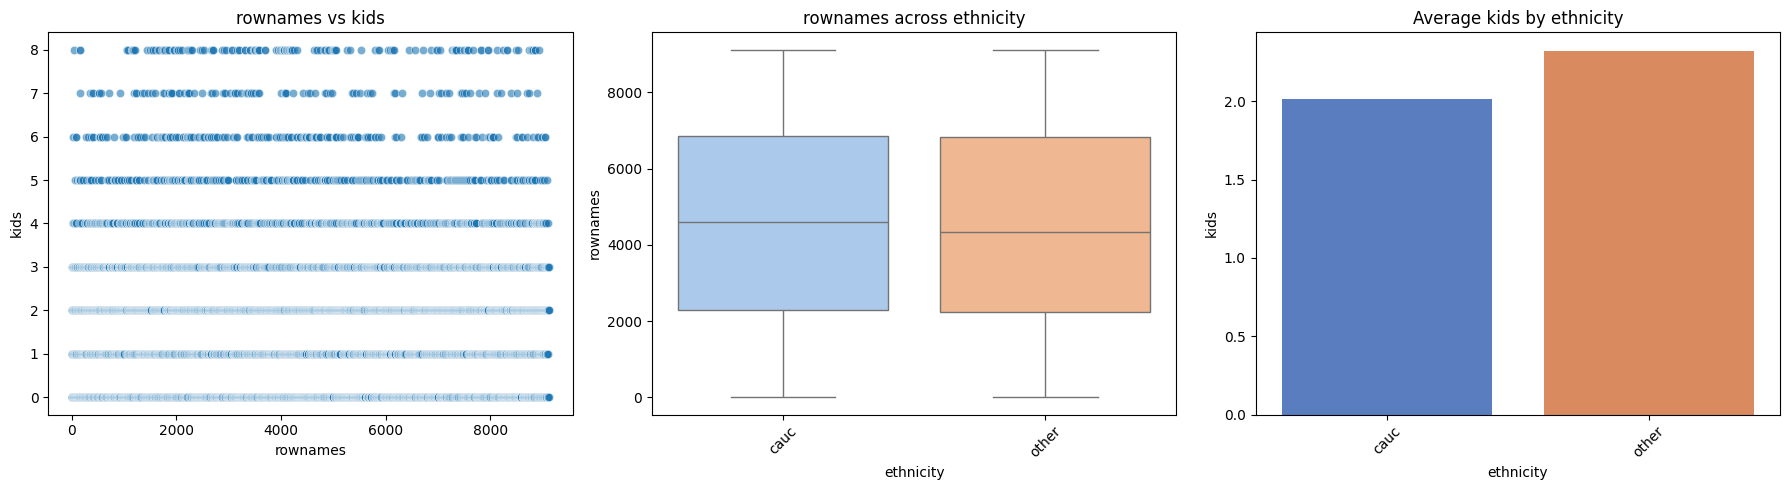

In [8]:
# Visualizing relationships between two variables
plt.figure(figsize=(18, 5))

# Plot 1: Scatter plot between first two numerical columns
plt.subplot(1, 3, 1)
sns.scatterplot(x=df[num_cols[0]], y=df[num_cols[1]], alpha=0.6)
plt.title(f'{num_cols[0]} vs {num_cols[1]}')

# Plot 2: Boxplot comparing a categorical and a numerical variable
plt.subplot(1, 3, 2)
sns.boxplot(x=df[cat_cols[0]], y=df[num_cols[0]], palette='pastel')
plt.title(f'{num_cols[0]} across {cat_cols[0]}')
plt.xticks(rotation=45)

# Plot 3: Barplot comparing categorical with another numerical variable
plt.subplot(1, 3, 3)
sns.barplot(x=df[cat_cols[0]], y=df[num_cols[1]], palette='muted', errorbar=None)
plt.title(f'Average {num_cols[1]} by {cat_cols[0]}')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

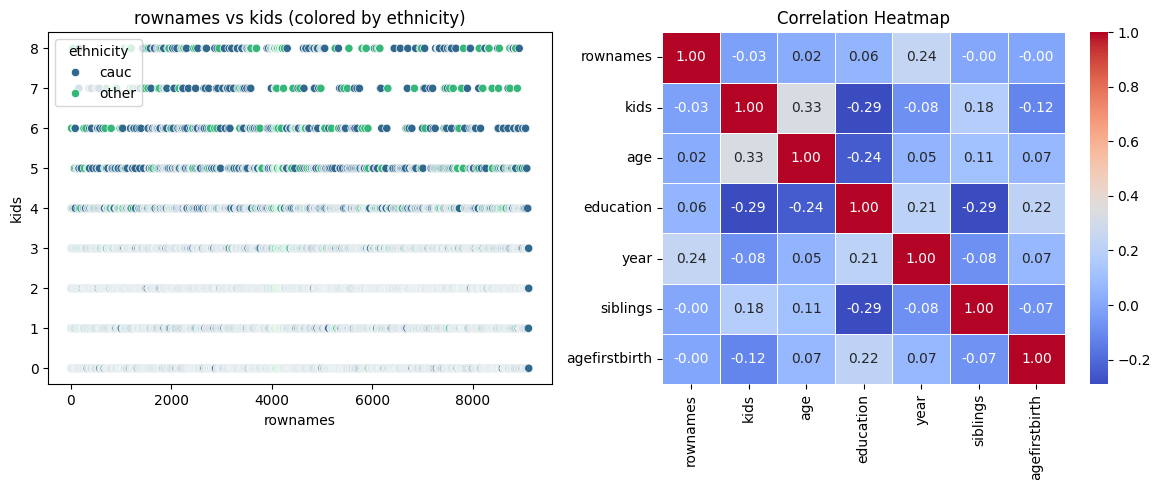


Plot 3: Pairplot (subset of numerical variables + hue)


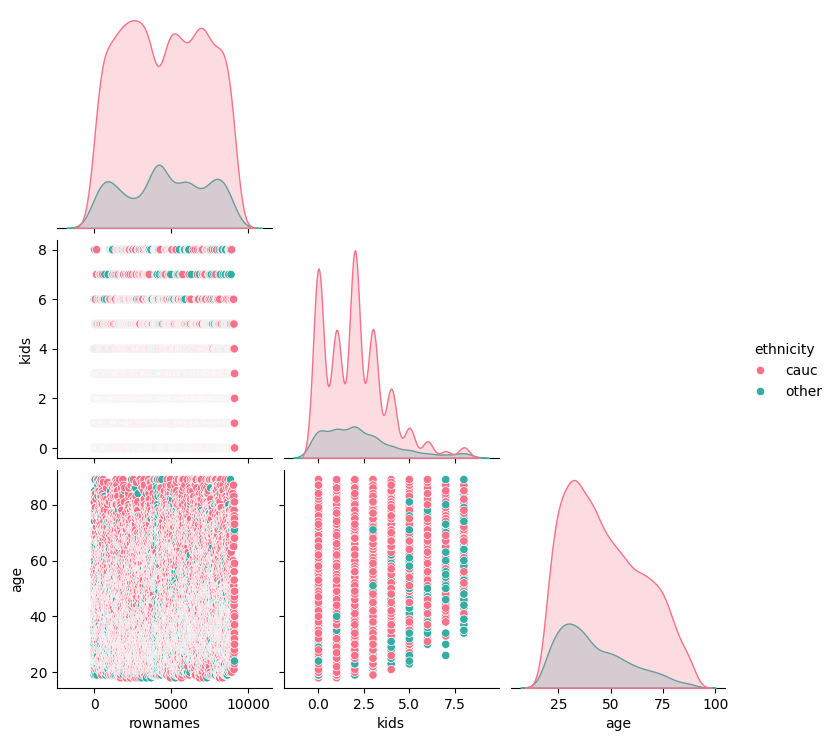

In [9]:
# Visualizing relationships between three or more variables
plt.figure(figsize=(18, 5))

# Plot 1: Scatter plot with a hue (3 variables: 2 numerical, 1 categorical)
plt.subplot(1, 3, 1)
sns.scatterplot(x=df[num_cols[0]], y=df[num_cols[1]], hue=df[cat_cols[0]], palette='viridis')
plt.title(f'{num_cols[0]} vs {num_cols[1]} (colored by {cat_cols[0]})')

# Plot 2: Correlation Heatmap (All numerical variables)
plt.subplot(1, 3, 2)
correlation_matrix = df[num_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')

# Plot 3: Pairplot (Selecting a subset to avoid massive rendering times)
# Note: Pairplot creates its own figure, so we call it separately
plt.tight_layout()
plt.show()

print("\nPlot 3: Pairplot (subset of numerical variables + hue)")
# Selecting first 3 numerical cols + 1 categorical for the pairplot to keep it readable
cols_to_plot = list(num_cols[:3]) + [cat_cols[0]]
sns.pairplot(df[cols_to_plot], hue=cat_cols[0], palette='husl', corner=True)
plt.show()

--- 1D Statistical Analysis (Skewness & Kurtosis) ---
Skewness:
 rownames         0.000000
kids             0.999912
age              0.476581
education       -0.262000
year            -0.356194
siblings         1.671257
agefirstbirth    1.823240
dtype: float64

Kurtosis:
 rownames        -1.200000
kids             1.027700
age             -0.780208
education        1.027897
year            -1.158102
siblings         4.788645
agefirstbirth    7.563951
dtype: float64

--- 3D Statistical Visualization ---


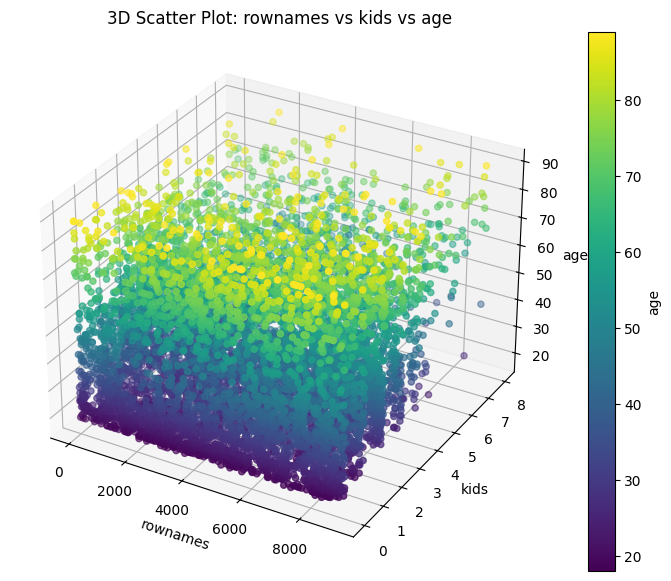

In [10]:
# Advanced 1D & 2D Stats, and 3D Visualization ---
from mpl_toolkits.mplot3d import Axes3D

print("--- 1D Statistical Analysis (Skewness & Kurtosis) ---")
# Skewness measures asymmetry; Kurtosis measures the "tailedness" of the distribution
print("Skewness:\n", df[num_cols].skew())
print("\nKurtosis:\n", df[num_cols].kurtosis())

print("\n--- 3D Statistical Visualization ---")
# Ensure we have at least 3 numerical columns for a 3D plot
if len(num_cols) >= 3:
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')

    x_col, y_col, z_col = num_cols[0], num_cols[1], num_cols[2]

    # Create 3D scatter plot
    scatter = ax.scatter(df[x_col], df[y_col], df[z_col], c=df[z_col], cmap='viridis', marker='o')

    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.set_zlabel(z_col)
    ax.set_title(f'3D Scatter Plot: {x_col} vs {y_col} vs {z_col}')

    fig.colorbar(scatter, label=z_col)
    plt.show()
else:
    print("Not enough numerical columns for 3D plotting.")

In [11]:
#Scaling Data for Clustering ---
from sklearn.preprocessing import StandardScaler

# Select only numerical columns for clustering
cluster_data = df[num_cols].copy()

# Standardize the data (mean=0, variance=1)
scaler = StandardScaler()
scaled_data = scaler.fit_transform(cluster_data)

print("Data successfully scaled for clustering algorithms.")

Data successfully scaled for clustering algorithms.


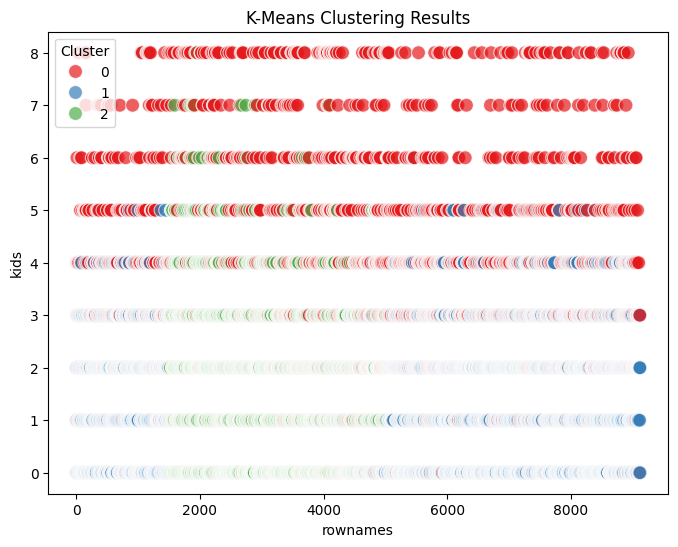

In [12]:
# K-Means Clustering
from sklearn.cluster import KMeans

# Initialize KMeans with 3 clusters (you can adjust this number)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Fit the model and assign cluster labels to the original dataframe
df['KMeans_Cluster'] = kmeans.fit_predict(scaled_data)

# Visualize the K-Means clusters in 2D (using the first two numerical columns)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=cluster_data.iloc[:, 0], y=cluster_data.iloc[:, 1],
                hue=df['KMeans_Cluster'], palette='Set1', s=100, alpha=0.7)
plt.title('K-Means Clustering Results')
plt.xlabel(num_cols[0])
plt.ylabel(num_cols[1])
plt.legend(title='Cluster')
plt.show()

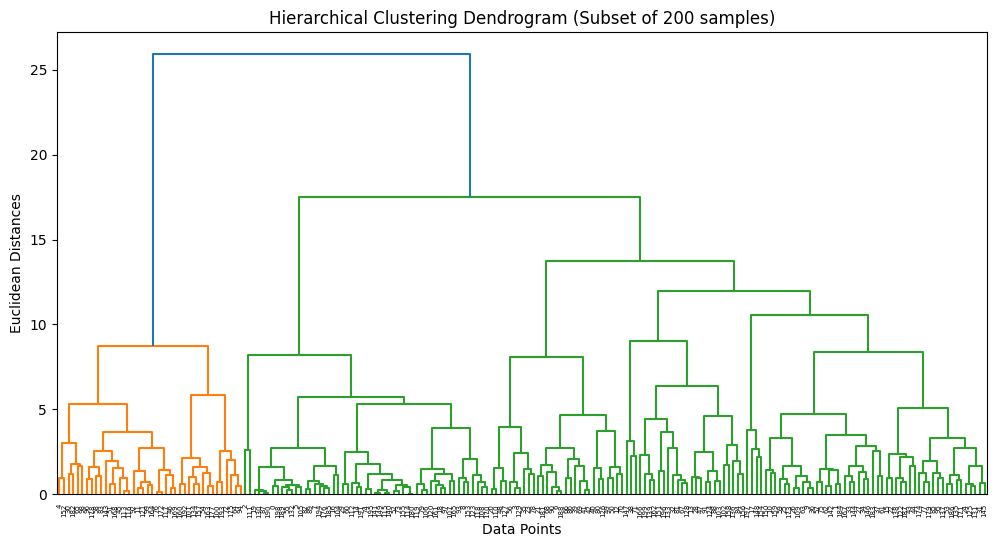

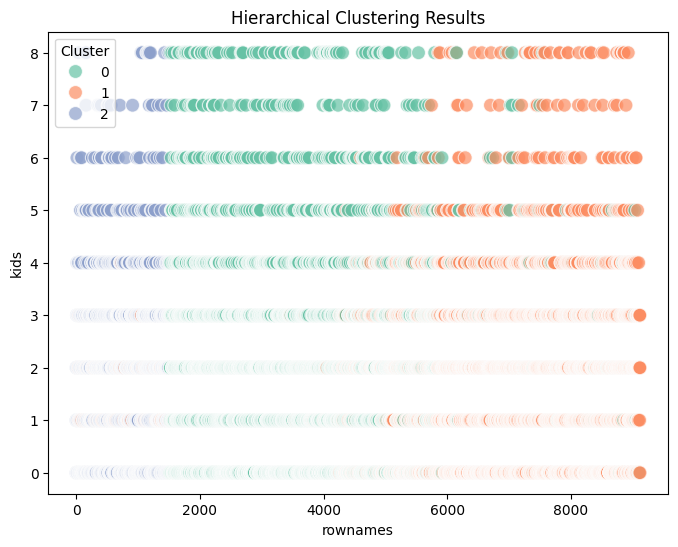

In [13]:
#Hierarchical Clustering
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering

# Plotting the Dendrogram using a subset (first 200 rows) for visibility and memory efficiency
plt.figure(figsize=(12, 6))
dendrogram = sch.dendrogram(sch.linkage(scaled_data[:200], method='ward'))
plt.title('Hierarchical Clustering Dendrogram (Subset of 200 samples)')
plt.xlabel('Data Points')
plt.ylabel('Euclidean Distances')
plt.show()

# Applying Agglomerative Hierarchical Clustering to the full dataset
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df['Hierarchical_Cluster'] = hc.fit_predict(scaled_data)

# Visualize Hierarchical clusters in 2D
plt.figure(figsize=(8, 6))
sns.scatterplot(x=cluster_data.iloc[:, 0], y=cluster_data.iloc[:, 1],
                hue=df['Hierarchical_Cluster'], palette='Set2', s=100, alpha=0.7)
plt.title('Hierarchical Clustering Results')
plt.xlabel(num_cols[0])
plt.ylabel(num_cols[1])
plt.legend(title='Cluster')
plt.show()

--- PCA Explained Variance ---
Variance explained by PC1: 26.14%
Variance explained by PC2: 18.05%
Variance explained by PC3: 15.13%
Cumulative Variance (3 components): 59.31%



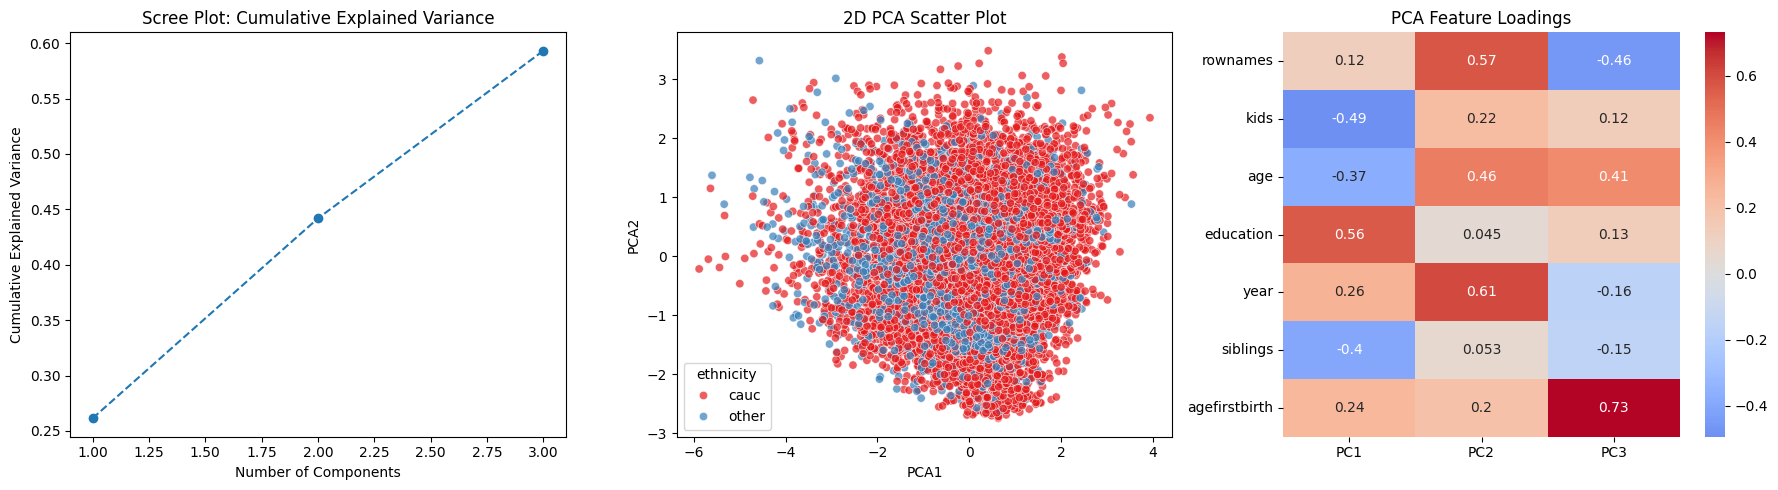

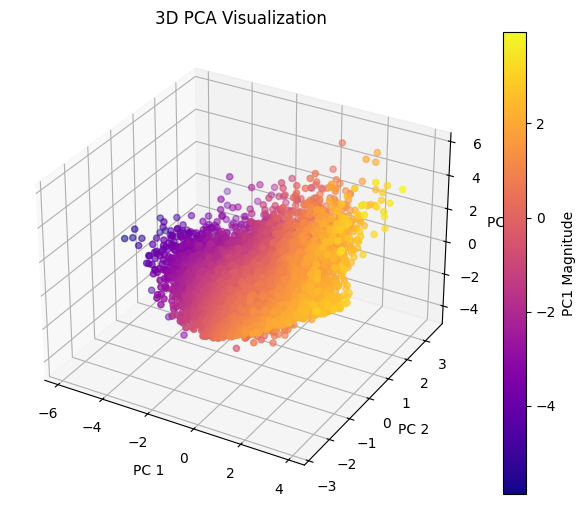

In [14]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Standardize data
scaler_pca = StandardScaler()
scaled_pca_data = scaler_pca.fit_transform(df[num_cols])

# Apply PCA for 3 components (for 3D plotting)
pca_full = PCA(n_components=3, random_state=42)
pca_result_full = pca_full.fit_transform(scaled_pca_data)
df['PCA1'] = pca_result_full[:, 0]
df['PCA2'] = pca_result_full[:, 1]
df['PCA3'] = pca_result_full[:, 2]

# Text Outputs
print("--- PCA Explained Variance ---")
print(f"Variance explained by PC1: {pca_full.explained_variance_ratio_[0]*100:.2f}%")
print(f"Variance explained by PC2: {pca_full.explained_variance_ratio_[1]*100:.2f}%")
print(f"Variance explained by PC3: {pca_full.explained_variance_ratio_[2]*100:.2f}%")
print(f"Cumulative Variance (3 components): {np.sum(pca_full.explained_variance_ratio_)*100:.2f}%\n")

# Graph 1: Scree Plot (Cumulative Variance)
plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 1)
plt.plot(range(1, 4), np.cumsum(pca_full.explained_variance_ratio_), marker='o', linestyle='--')
plt.title('Scree Plot: Cumulative Explained Variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')

# Graph 2: 2D PCA Plot colored by a categorical variable
plt.subplot(1, 3, 2)
sns.scatterplot(x='PCA1', y='PCA2', hue=df[cat_cols[0]], data=df, palette='Set1', alpha=0.7)
plt.title('2D PCA Scatter Plot')

# Graph 3: PCA Feature Loadings Heatmap
plt.subplot(1, 3, 3)
loadings = pd.DataFrame(pca_full.components_.T, columns=['PC1', 'PC2', 'PC3'], index=num_cols)
sns.heatmap(loadings, annot=True, cmap='coolwarm', center=0)
plt.title('PCA Feature Loadings')
plt.tight_layout()
plt.show()

# Graph 4: 3D PCA Plot
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
scatter_3d = ax.scatter(df['PCA1'], df['PCA2'], df['PCA3'], c=df['PCA1'], cmap='plasma')
ax.set_xlabel('PC 1')
ax.set_ylabel('PC 2')
ax.set_zlabel('PC 3')
ax.set_title('3D PCA Visualization')
fig.colorbar(scatter_3d, label='PC1 Magnitude')
plt.show()

--- SLR Equation and Metrics (rownames vs kids) ---
Equation: kids = -0.0000 * rownames + 2.1635
R-squared (R2): -0.0006
Mean Squared Error (MSE): 3.3363
Mean Absolute Error (MAE): 1.3772



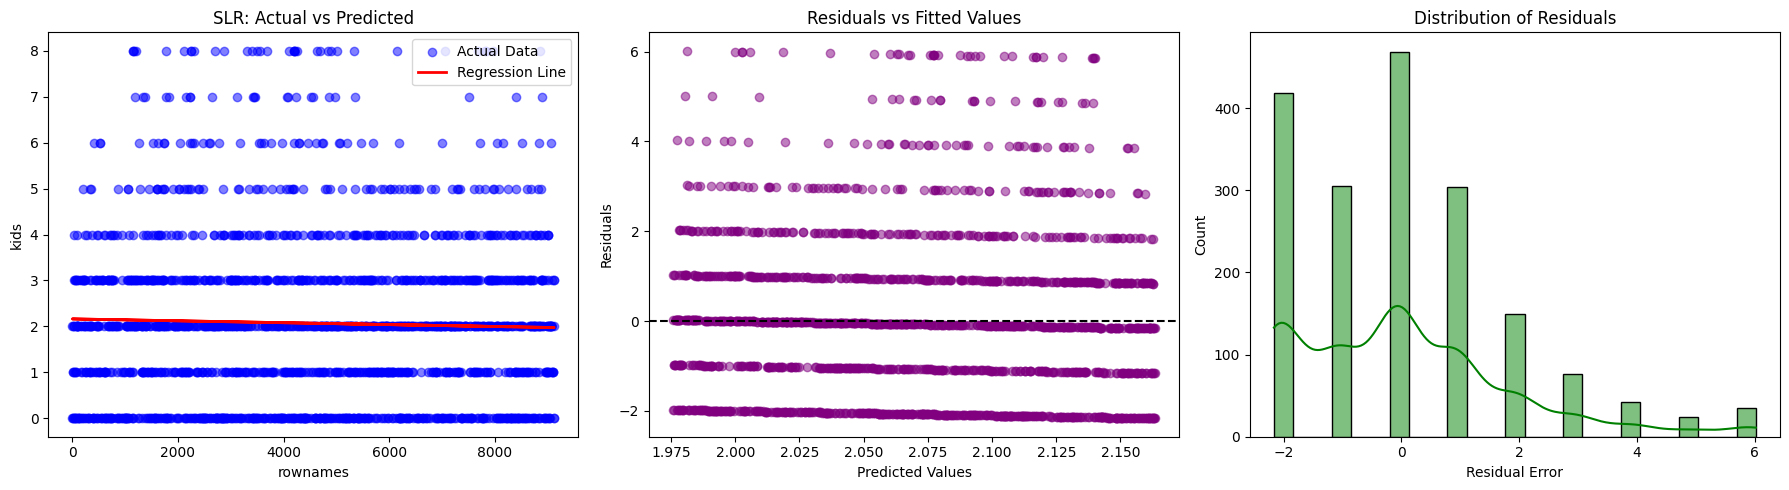

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X_col, y_col = num_cols[0], num_cols[1]
X = df[[X_col]]
y = df[y_col]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

slr_model = LinearRegression()
slr_model.fit(X_train, y_train)
y_pred = slr_model.predict(X_test)
residuals = y_test - y_pred

# Text Outputs
print(f"--- SLR Equation and Metrics ({X_col} vs {y_col}) ---")
print(f"Equation: {y_col} = {slr_model.coef_[0]:.4f} * {X_col} + {slr_model.intercept_:.4f}")
print(f"R-squared (R2): {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Mean Absolute Error (MAE): {mean_absolute_error(y_test, y_pred):.4f}\n")

plt.figure(figsize=(18, 5))

# Graph 1: Regression Line
plt.subplot(1, 3, 1)
plt.scatter(X_test, y_test, color='blue', alpha=0.5, label='Actual Data')
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Regression Line')
plt.title('SLR: Actual vs Predicted')
plt.xlabel(X_col)
plt.ylabel(y_col)
plt.legend()

# Graph 2: Residuals vs Fitted Values (Checking for homoscedasticity)
plt.subplot(1, 3, 2)
plt.scatter(y_pred, residuals, color='purple', alpha=0.5)
plt.axhline(y=0, color='black', linestyle='--')
plt.title('Residuals vs Fitted Values')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')

# Graph 3: Distribution of Residuals (Checking for normality)
plt.subplot(1, 3, 3)
sns.histplot(residuals, kde=True, color='green')
plt.title('Distribution of Residuals')
plt.xlabel('Residual Error')
plt.tight_layout()
plt.show()